# VYNDRA Analytics Notebook
This notebook-style Python file is intentionally cache-driven: it reads saved CSV/JSON results
and does not scan large image datasets. Run the analysis scripts first, then execute this file
cell-by-cell in VS Code/Jupyter or run `python notebooks/VYNDRA_analytics.py`.

## Observation vs inference
Each figure has a title and labelled axes. Printed interpretation distinguishes what the plot
directly shows (observation) from plausible explanations (inference).

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if not (ROOT / "data/raw/Db.csv").exists():
    ROOT = Path.cwd().parent
RESULTS = ROOT / "results/tables"
FIGURES = ROOT / "results/figures"
FIGURES.mkdir(parents=True, exist_ok=True)

## 1. Nutrition-table quality and preprocessing
The nutrition table stores values per 100 g. This section calculates missingness, duplicates,
outliers, kJ/kcal ratios and an Atwater-style energy consistency check from the current data.
These checks are descriptive and do not establish that source values are medically accurate.

In [2]:
foods = pd.read_csv(ROOT / "data/raw/Db.csv")
print("Nutrition rows:", len(foods))
print("Columns:", list(foods.columns))
print("Missing values by column:\n", foods.isna().sum().to_string())
print("Exact duplicate rows:", int(foods.duplicated().sum()))
print("Duplicate food names:", int(foods.food_name.duplicated().sum()))
macro_cols = [c for c in ["energy_kcal", "protein_g", "carb_g", "fat_g", "fibre_g"] if c in foods]
print("Macro summary:\n", foods[macro_cols].describe(percentiles=[.01,.25,.5,.75,.99]).round(2).to_string())
for column in macro_cols:
    values = pd.to_numeric(foods[column], errors="coerce").dropna()
    q1, q3 = values.quantile(.25), values.quantile(.75)
    iqr = q3 - q1
    outlier_mask = (pd.to_numeric(foods[column], errors="coerce") < q1 - 1.5*iqr) | (pd.to_numeric(foods[column], errors="coerce") > q3 + 1.5*iqr)
    print(f"IQR outliers for {column}:", int(outlier_mask.sum()))

Nutrition rows: 1014
Columns: ['food_code', 'food_name', 'energy_kj', 'energy_kcal', 'carb_g', 'protein_g', 'fat_g', 'fibre_g']
Missing values by column:
 food_code      0
food_name      0
energy_kj      0
energy_kcal    0
carb_g         0
protein_g      0
fat_g          0
fibre_g        0
Exact duplicate rows: 0
Duplicate food names: 0
Macro summary:
        energy_kcal  protein_g   carb_g    fat_g  fibre_g
count      1014.00    1014.00  1014.00  1014.00  1014.00
mean        233.74       4.75    18.35    16.27     1.96
std         187.60       3.44    16.75    20.45     2.77
min           6.61       0.00     0.00     0.00     0.00
1%           16.16       0.11     0.37     0.03     0.00
25%         101.18       2.10     5.58     4.03     0.59
50%         174.92       3.99    11.92     9.09     1.33
75%         315.85       6.60    26.87    17.08     2.35
99%         777.41      15.62    66.64    82.34    11.41
max         839.33      21.55    86.53    90.45    35.71
IQR outliers for e

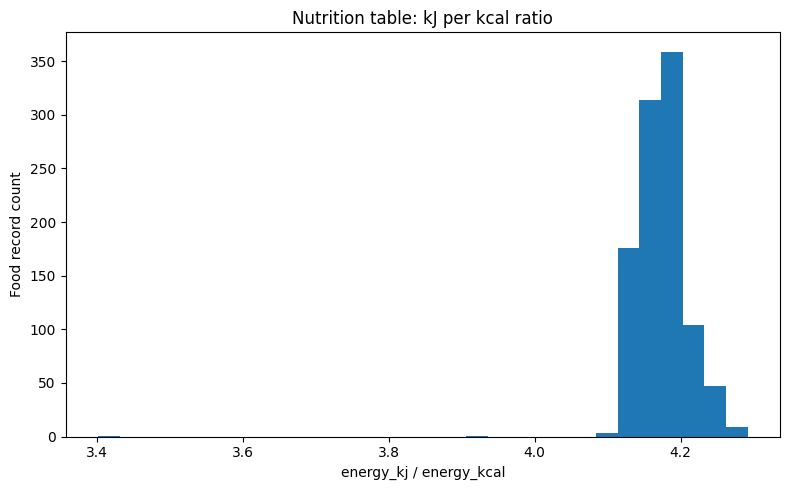

Observation: ratio range = 3.401 to 4.292
Inference: extreme ratios can indicate source or conversion inconsistencies; inspect individual rows before changing values.


In [3]:
if {"energy_kj", "energy_kcal"}.issubset(foods.columns):
    valid = foods[(foods.energy_kcal > 0) & (foods.energy_kj > 0)].copy()
    valid["kj_per_kcal"] = valid.energy_kj / valid.energy_kcal
    fig, ax = plt.subplots(figsize=(8, 5))
    ax.hist(valid.kj_per_kcal, bins=30)
    ax.set_title("Nutrition table: kJ per kcal ratio")
    ax.set_xlabel("energy_kj / energy_kcal")
    ax.set_ylabel("Food record count")
    fig.tight_layout(); fig.savefig(FIGURES / "nutrition_kj_kcal_ratio.png", dpi=160); plt.show()
    print("Observation: ratio range =", round(valid.kj_per_kcal.min(), 3), "to", round(valid.kj_per_kcal.max(), 3))
    print("Inference: extreme ratios can indicate source or conversion inconsistencies; inspect individual rows before changing values.")

Atwater records within 10%: 973 of 1014 ( 95.96 %)
Largest Atwater differences:
                    food_name  energy_kcal  atwater_kcal  relative_difference
               Egg drop soup        26.64        177.80             5.674174
     Chicken sweet corn soup        28.32        177.75             5.276483
 Meat consomme (with mutton)        29.76        184.60             5.202957
      Consomme au vermicelli        29.94        182.94             5.110220
Spinach soup (Palak ka soup)        32.59        182.62             4.603559
        Consomme au julienne        27.76        151.86             4.470461
                 Cheese soup        41.13        210.67             4.122052
                 Lentil soup        31.17        159.48             4.116458
              Talaumein soup        35.63        172.18             3.832445
Classic seasoned black beans        28.78        137.20             3.767199


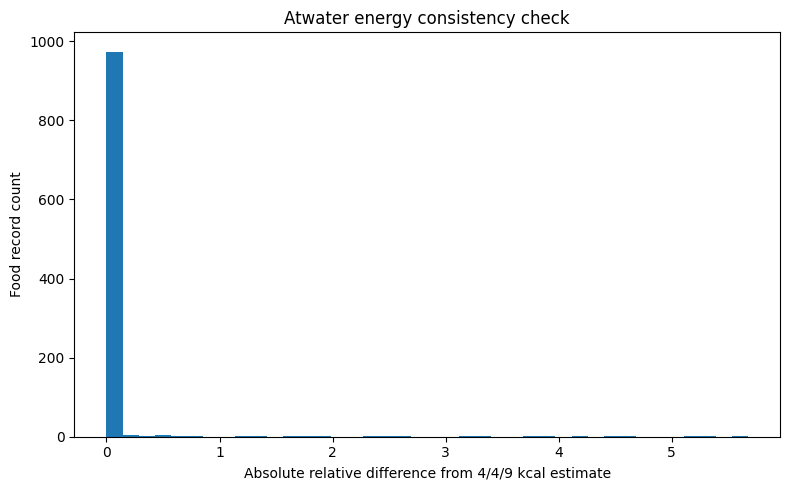

Observation: the histogram and calculated proportion show agreement with the simplified 4/4/9 rule.
Inference: fibre, food-specific energy factors, rounding, and source inconsistencies can explain deviations; the check is not a correction rule.


In [4]:
if {"energy_kcal", "protein_g", "carb_g", "fat_g"}.issubset(foods.columns):
    check = foods.copy()
    check["atwater_kcal"] = 4*check.protein_g + 4*check.carb_g + 9*check.fat_g
    check["relative_difference"] = (check.energy_kcal-check.atwater_kcal).abs()/check.energy_kcal.replace(0,np.nan)
    valid = check.relative_difference.dropna()
    print("Atwater records within 10%:", int((valid <= .10).sum()), "of", len(valid), "(", round((valid <= .10).mean()*100, 2), "%)")
    print("Largest Atwater differences:\n", check.nlargest(10,"relative_difference")[["food_name","energy_kcal","atwater_kcal","relative_difference"]].to_string(index=False))
    fig, ax = plt.subplots(figsize=(8,5)); ax.hist(valid, bins=40)
    ax.set_title("Atwater energy consistency check")
    ax.set_xlabel("Absolute relative difference from 4/4/9 kcal estimate")
    ax.set_ylabel("Food record count"); fig.tight_layout(); fig.savefig(FIGURES / "nutrition_atwater_check.png", dpi=160); plt.show()
    print("Observation: the histogram and calculated proportion show agreement with the simplified 4/4/9 rule.")
    print("Inference: fibre, food-specific energy factors, rounding, and source inconsistencies can explain deviations; the check is not a correction rule.")

## 2. Portion-size cleaning
The cleaned serving estimate is unit_serving_energy_kcal / energy_kcal * 100. Missing or
out-of-range serving estimates are handled by the documented 100 g fallback in portions.py.

Serving records: 1014 valid estimates: 907 missing/out-of-range/default candidates: 107


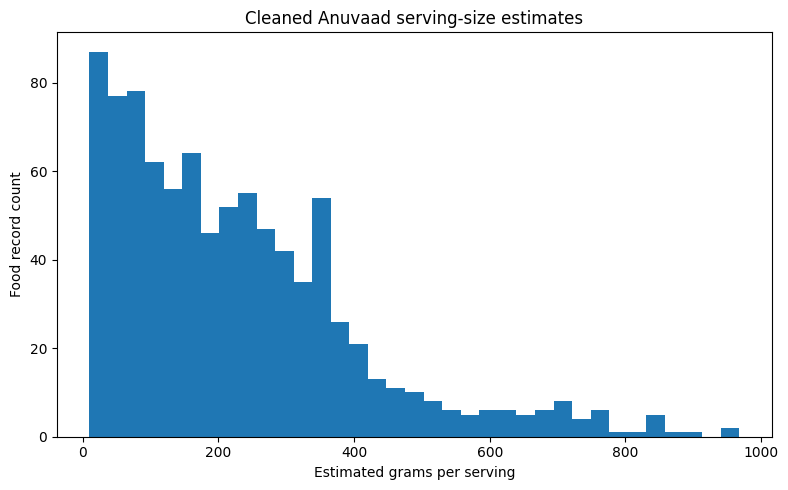

Observation: valid serving estimates are limited to records with a serving unit and a 5–1,000 g estimate.
Inference: out-of-range estimates are treated as unreliable and use the documented 100 g fallback in the API.
Reference-meal evaluation is pending. Fill /Volumes/SANDISK/VYNDRA-backend/data/processed/reference_meals_template.csv then run scripts/evaluate_portions.py.


In [5]:
serving_file = ROOT / "data/raw/Anuvaad_INDB_2024.11.xlsx"
if serving_file.exists():
    serving = pd.read_excel(serving_file)
    needed = {"food_name", "energy_kcal", "unit_serving_energy_kcal", "servings_unit"}
    if needed.issubset(serving.columns):
        serving["energy_kcal"] = pd.to_numeric(serving["energy_kcal"], errors="coerce")
        serving["unit_serving_energy_kcal"] = pd.to_numeric(serving["unit_serving_energy_kcal"], errors="coerce")
        serving["estimated_grams"] = serving["unit_serving_energy_kcal"] / serving["energy_kcal"] * 100
        serving["valid_serving"] = serving["servings_unit"].fillna("").astype(str).str.strip().ne("") & serving["estimated_grams"].between(5, 1000) & serving["estimated_grams"].notna()
        print("Serving records:", len(serving), "valid estimates:", int(serving.valid_serving.sum()), "missing/out-of-range/default candidates:", int((~serving.valid_serving).sum()))
        fig, ax = plt.subplots(figsize=(8,5)); ax.hist(serving.loc[serving.valid_serving, "estimated_grams"], bins=35)
        ax.set_title("Cleaned Anuvaad serving-size estimates")
        ax.set_xlabel("Estimated grams per serving")
        ax.set_ylabel("Food record count"); fig.tight_layout(); fig.savefig(FIGURES / "portion_serving_size_cleaning.png", dpi=160); plt.show()
        print("Observation: valid serving estimates are limited to records with a serving unit and a 5–1,000 g estimate.")
        print("Inference: out-of-range estimates are treated as unreliable and use the documented 100 g fallback in the API.")
    else:
        print("Serving workbook is missing required columns:", sorted(needed - set(serving.columns)))
portion_results = RESULTS / "portion_evaluation.csv"
if portion_results.exists():
    print(pd.read_csv(portion_results).describe(include="all").to_string())
else:
    template = ROOT / "data/processed/reference_meals_template.csv"
    print("Reference-meal evaluation is pending. Fill", template, "then run scripts/evaluate_portions.py.")

## 3. Text analytics
Results are loaded from the saved experiment outputs; the notebook does not retrain models.

vectorizer              model  validation_accuracy  accuracy  macro_precision  macro_recall  macro_f1
  bow_word      MultinomialNB             1.000000  1.000000         1.000000      1.000000  1.000000
  bow_word LogisticRegression             1.000000  1.000000         1.000000      1.000000  1.000000
  bow_word          LinearSVC             1.000000  1.000000         1.000000      1.000000  1.000000
  bow_word       DecisionTree             1.000000  1.000000         1.000000      1.000000  1.000000
tfidf_word      MultinomialNB             1.000000  1.000000         1.000000      1.000000  1.000000
tfidf_word LogisticRegression             1.000000  1.000000         1.000000      1.000000  1.000000
tfidf_word          LinearSVC             1.000000  1.000000         1.000000      1.000000  1.000000
tfidf_char      MultinomialNB             1.000000  1.000000         1.000000      1.000000  1.000000
tfidf_char LogisticRegression             1.000000  1.000000         1.000000     

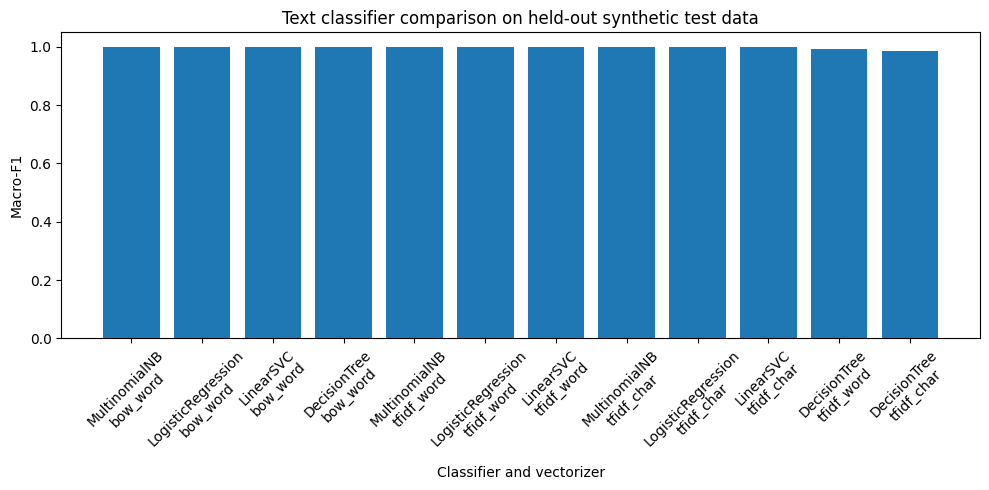

Observation: bars compare held-out metrics on synthetic messages.
Inference: synthetic/template data can overstate performance; use the separately reviewed hand-written test set before choosing a production threshold.


In [6]:
text_path = RESULTS / "part4/text_model_comparison.csv"
if text_path.exists():
    text_results = pd.read_csv(text_path).sort_values("macro_f1", ascending=False)
    print(text_results.to_string(index=False))
    fig, ax = plt.subplots(figsize=(10,5))
    ax.bar(text_results.model + "\n" + text_results.vectorizer, text_results.macro_f1)
    ax.set_title("Text classifier comparison on held-out synthetic test data")
    ax.set_xlabel("Classifier and vectorizer")
    ax.set_ylabel("Macro-F1")
    ax.tick_params(axis="x", labelrotation=45); fig.tight_layout(); fig.savefig(FIGURES / "text_model_comparison.png", dpi=160); plt.show()
    print("Observation: bars compare held-out metrics on synthetic messages.")
    print("Inference: synthetic/template data can overstate performance; use the separately reviewed hand-written test set before choosing a production threshold.")
else: print("Text results not found; run scripts/make_chat_dataset.py and scripts/run_text_analytics.py.")

## 4. Social network analysis

user_id  in_degree  out_degree  betweenness  closeness  eigenvector  pagerank  community  planted_community
   u030         45          29     0.017126   0.590000     0.121582  0.023287          1                  1
   u022         43          24     0.028332   0.634409     0.136112  0.023189          1                  1
   u051         41          35     0.018088   0.595960     0.162086  0.023022          3                  3
   u050         39          20     0.008548   0.602041     0.147420  0.022356          3                  3
   u052         38          30     0.015553   0.602041     0.163773  0.021329          3                  3
   u043         41          41     0.032683   0.621053     0.156158  0.020870          2                  2
   u035         43          32     0.013053   0.590000     0.147982  0.020838          2                  2
   u032         42          35     0.008176   0.567308     0.186132  0.020676          2                  2
   u046         38          

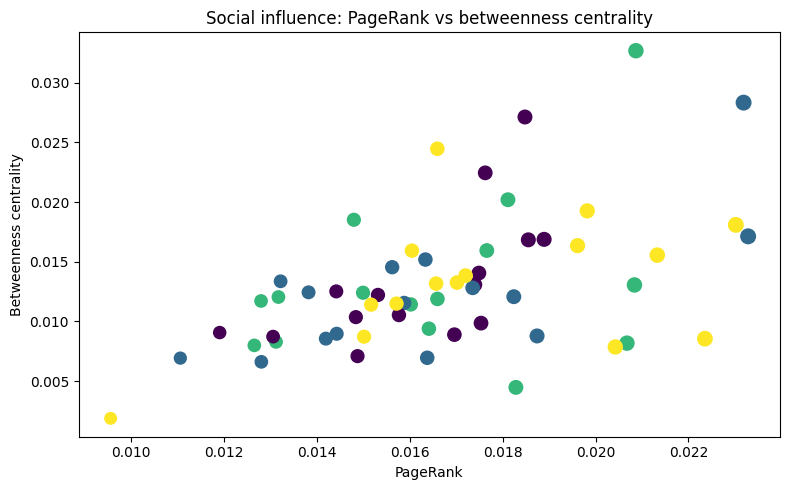

Observation: each point is a synthetic user; point size is scaled by PageRank and colour denotes detected community.
Inference: high centrality indicates structural prominence in this generated graph, not real-world influence.


In [7]:
social_path = RESULTS / "part5/social_centrality.csv"
if social_path.exists():
    social = pd.read_csv(social_path)
    print(social.head(10).to_string(index=False))
    fig, ax = plt.subplots(figsize=(8,5)); ax.scatter(social.pagerank, social.betweenness, c=social.community, s=40+social.pagerank*3000)
    ax.set_title("Social influence: PageRank vs betweenness centrality")
    ax.set_xlabel("PageRank"); ax.set_ylabel("Betweenness centrality"); fig.tight_layout(); fig.savefig(FIGURES / "social_centrality_comparison.png", dpi=160); plt.show()
    print("Observation: each point is a synthetic user; point size is scaled by PageRank and colour denotes detected community.")
    print("Inference: high centrality indicates structural prominence in this generated graph, not real-world influence.")
else: print("Social results not found; run scripts/make_social_data.py and scripts/run_social_analytics.py.")

## 5. Nutrition clustering

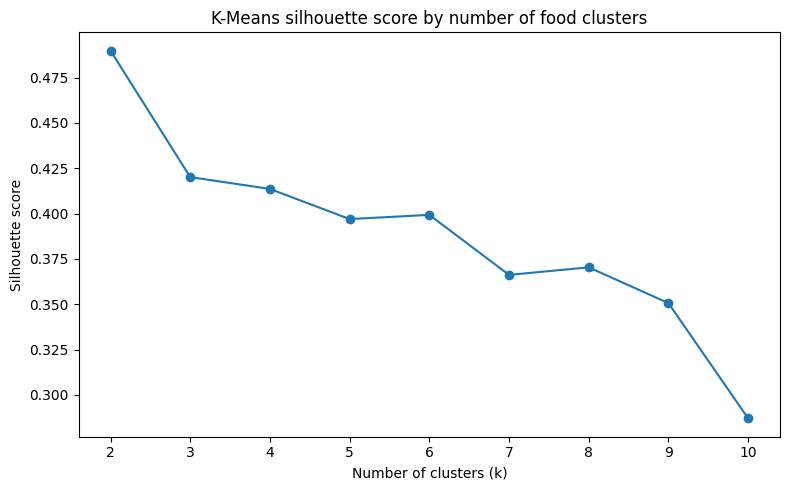

 k  silhouette  davies_bouldin
 2    0.489839        0.680589
 3    0.420121        1.050663
 4    0.413585        0.895311
 5    0.396965        0.840848
 6    0.399281        0.834578
 7    0.366171        0.976748
 8    0.370342        0.942038
 9    0.350602        0.940539
10    0.287038        1.031800
Observation: silhouette measures separation and cohesion under the selected scaled macro features.
Inference: the maximum score is a useful selection heuristic, not proof that the groups are natural food categories.


In [8]:
cluster_path = RESULTS / "part6/food_kmeans_metrics.csv"
if cluster_path.exists():
    cluster_metrics = pd.read_csv(cluster_path)
    fig, ax = plt.subplots(figsize=(8,5)); ax.plot(cluster_metrics.k, cluster_metrics.silhouette, marker="o")
    ax.set_title("K-Means silhouette score by number of food clusters")
    ax.set_xlabel("Number of clusters (k)"); ax.set_ylabel("Silhouette score"); fig.tight_layout(); fig.savefig(FIGURES / "food_silhouette_by_k.png", dpi=160); plt.show()
    print(cluster_metrics.to_string(index=False))
    print("Observation: silhouette measures separation and cohesion under the selected scaled macro features.")
    print("Inference: the maximum score is a useful selection heuristic, not proof that the groups are natural food categories.")
else: print("Food clustering results not found; run scripts/cluster_foods.py.")

## 6. Vision evaluation

In [9]:
vision_path = RESULTS / "part7/vision_evaluation_summary.json"
if vision_path.exists():
    print(json.dumps(json.loads(vision_path.read_text()), indent=2))
else: print("Vision results not found; prepare the manifest and run scripts/evaluate_vision_suite.py.")

{
  "manifest_rows": 690,
  "successfully_predicted_rows": 690,
  "classical_baseline_classes": 15,
  "classical_baseline_images": 1500,
  "classical_baseline_target_classes": 15,
  "classical_baseline_target_images_per_class": 100,
  "top1_accuracy_accepted_classes": 0.30434782608695654,
  "top1_accuracy_primary_class": 0.2826086956521739,
  "top3_accuracy_accepted_classes": 0.5014492753623189,
  "mean_confidence_when_correct": 0.5674010333333332,
  "mean_confidence_when_wrong": 0.33086155416666674,
  "macro_precision_supported_classes": 0.7196297249260034,
  "macro_recall_supported_classes": 0.2719298245614035,
  "macro_f1_supported_classes": 0.36004517464833635,
  "class_support": {
    "allo gobi": 60,
    "chappati": 60,
    "gulab jamoon": 60,
    "biryani": 60,
    "idly": 30,
    "kulfi": 30,
    "uthappam": 30,
    "mutton  seekh kebab": 30,
    "palak panner": 30,
    "medu vada": 30,
    "masala dosa": 30,
    "fish curry": 30,
    "garlice naan": 30,
    "chole chickpea cur

## 7. Realistic check: food-intent model on the hand-written review set
Section 3 scores classifiers on synthetic template messages, where near-perfect results are expected.
This section scores the saved model (`models/food_intent.joblib`) on 150 separately written messages.
Labels in that file still need a human review pass before they count as gold-standard.

Review-set messages: 150 | accuracy 0.707 | macro-F1 0.697
                 precision  recall  f1-score  support
food_intent          0.722    0.52     0.605     50.0
food_discussion      0.694    0.68     0.687     50.0
not_food             0.708    0.92     0.800     50.0


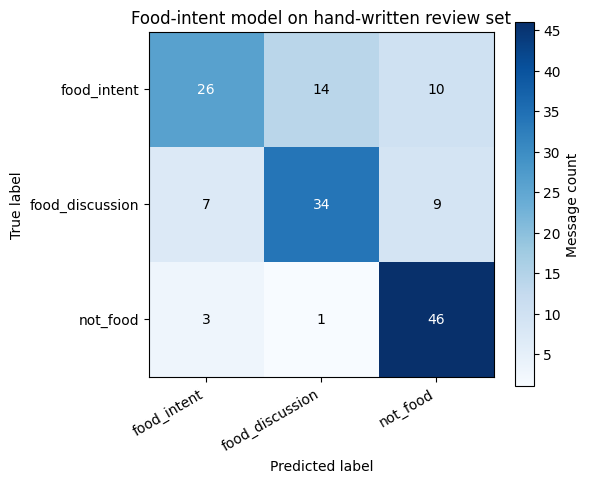

Observation: accuracy on realistic messages is much lower than on synthetic templates.
Inference: template-generated training data does not cover real slang and phrasing; synthetic scores should not be quoted as expected real-world performance.


In [10]:
review_path = RESULTS / "part4/review_set_intent_metrics.json"
confusion_path = RESULTS / "part4/review_set_intent_confusion.csv"
if review_path.exists() and confusion_path.exists():
    review = json.loads(review_path.read_text(encoding="utf-8"))
    print(f"Review-set messages: {review['rows']} | accuracy {review['accuracy']:.3f} | macro-F1 {review['macro_f1']:.3f}")
    print(pd.DataFrame(review["per_class"]).T[["precision", "recall", "f1-score", "support"]].round(3).to_string())
    cm = pd.read_csv(confusion_path, index_col=0)
    fig, ax = plt.subplots(figsize=(6, 5))
    image = ax.imshow(cm.values, cmap="Blues")
    ax.set_xticks(range(len(cm.columns)), cm.columns, rotation=30, ha="right")
    ax.set_yticks(range(len(cm.index)), cm.index)
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(j, i, int(cm.iat[i, j]), ha="center", va="center",
                    color="white" if cm.iat[i, j] > cm.values.max() / 2 else "black")
    ax.set_title("Food-intent model on hand-written review set")
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("True label")
    fig.colorbar(image, ax=ax, label="Message count")
    fig.tight_layout(); plt.show()
    print("Observation: accuracy on realistic messages is much lower than on synthetic templates.")
    print("Inference: template-generated training data does not cover real slang and phrasing; "
          "synthetic scores should not be quoted as expected real-world performance.")
else:
    print("Review-set results not found; run: PYTHONPATH=. python scripts/evaluate_review_set.py")

## 8. Vision evaluation: by dataset, against baselines, and the saved confusion matrices


part7/vision_metrics_by_dataset.csv
           dataset  images  top1_accuracy_accepted  top3_accuracy_accepted  top1_accuracy_primary
indian_food_images     240                   0.338                   0.625                  0.338
             khana     450                   0.287                   0.436                  0.253

part7/vision_model_comparison.csv
          method  top1_accuracy  macro_precision_supported  macro_recall_supported  macro_f1_supported
    YOLO_best.pt          0.304                      0.720                   0.272               0.360
  HSV_GaussianNB          0.149                      0.193                   0.149               0.139
HSV_DecisionTree          0.261                      0.269                   0.261               0.262
         HSV_kNN          0.200                      0.231                   0.200               0.196


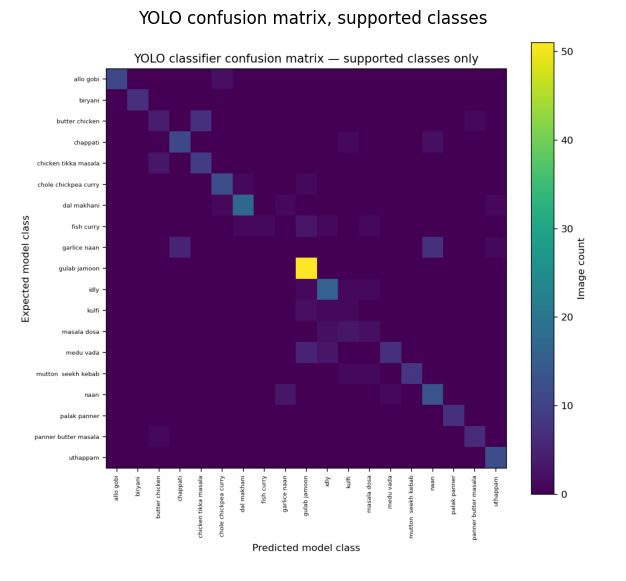

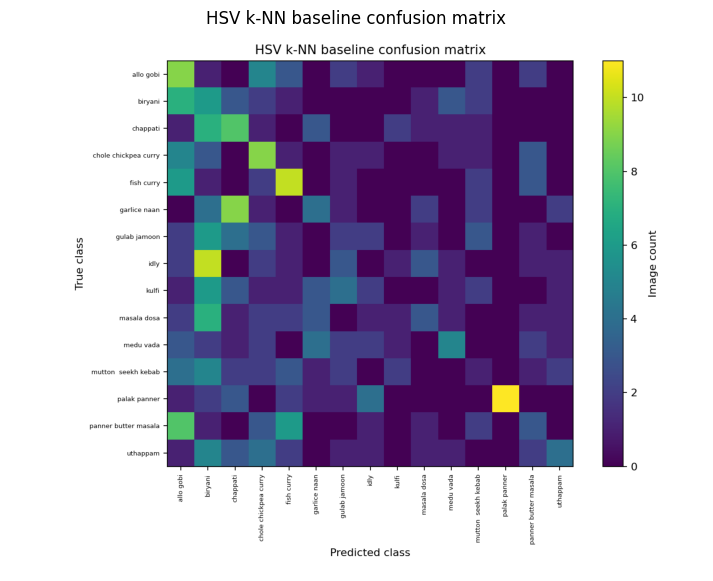

Observation: the YOLO model beats colour-histogram baselines but remains weak on external images.
Inference: the large gap to the training validation score points to domain shift between the training photos and the external datasets (the training-data provenance is not documented).


In [11]:
for name in ["part7/vision_metrics_by_dataset.csv", "part7/vision_model_comparison.csv"]:
    path = RESULTS / name
    print(f"\n{name}")
    print(pd.read_csv(path).round(3).to_string(index=False) if path.exists() else "  missing: run scripts/evaluate_vision_suite.py")
from matplotlib.image import imread
for name, title in [("part7/vision_confusion_supported.png", "YOLO confusion matrix, supported classes"),
                    ("part7/vision_baseline_confusion.png", "HSV k-NN baseline confusion matrix")]:
    path = FIGURES / name
    if path.exists():
        fig, ax = plt.subplots(figsize=(9, 7)); ax.imshow(imread(path)); ax.set_title(title); ax.axis("off"); plt.show()
print("Observation: the YOLO model beats colour-histogram baselines but remains weak on external images.")
print("Inference: the large gap to the training validation score points to domain shift between "
      "the training photos and the external datasets (the training-data provenance is not documented).")

# ## Limitations
# - Synthetic chat and social data are useful for reproducible method demonstrations, not evidence of real-user behaviour.
# - Food diet/mood/allergen tags are rule-generated from templates and need independent review.
# - The class-to-food mapping is a human-reviewed judgment; unmatched foods must not receive guessed nutrition.
# - The reported model validation score is not an independent test. External performance may be lower due to domain shift, mapping errors, and data leakage/unknown training provenance.
# - Nutrition values and serving sizes are estimates; the simplified Atwater check is diagnostic only.
# - This notebook reads cached results and intentionally does not rescan the large image datasets.